# Notebook 6 — conferência geométrica do piloto IFC2SB parcial

**CIV2155 · FNDE Tipo 2 · arquitetura ARQ-DTV R03 · cozinha.**

Pergunta: os sinais de sobreposição relatados no piloto dizem respeito à parede bruta, à geometria com aberturas subtraídas ou à região de cada abertura? Os registros permitem responder à questão arquitetônica pretendida?

O procedimento é **conferência interna da mesma fonte**, com nova leitura de geometrias e rastreio de relações declaradas. Não constitui validação por motor independente ou por planta/padrão-ouro externo. Não modifica IFC, RDF anterior, tolerâncias do recorte nem decisões arquitetônicas.

**Origem científica do módulo geométrico reutilizado:** [Fichter et al. (2021)](https://doi.org/10.26868/25222708.2021.30156), [IFC2SB dos autores, commit 96a89cd](https://github.com/RWTH-E3D/IFC2SB/tree/96a89cdff65f13279c0c3ce67e729ad9f9f5adad). A adaptação parcial está no Notebook 1 v04.

**Natureza do código novo:** rotinas específicas deste estudo para conferir hipóteses, inspecionar dados e produzir figuras. Não são apresentadas como algoritmo pronto do artigo. Fontes técnicas diretas: [IfcOpenShell, processamento geométrico](https://docs.ifcopenshell.org/ifcopenshell-python/geometry_processing.html) e [opção disable-opening-subtractions](https://docs.ifcopenshell.org/ifcopenshell/geometry_settings.html#disable-opening-subtractions). A documentação consultada é atual; a execução é fixada em IfcOpenShell 0.8.4 e OCP 7.8.1.


## 1. Preparação e integridade das fontes

Baixar somente quando necessário e conferir hashes. As dependências são verificadas no ambiente. O helper `ifc2sb_faces.py` é cópia byte a byte do módulo publicado na revisão 04, com atribuição e GPL preservadas.

In [1]:
from pathlib import Path
import sys,json,hashlib,urllib.request,importlib.util,subprocess
modulo=Path.cwd() if (Path.cwd()/'conferir.py').exists() else Path.cwd()/'conferencia_ifc2sb_v01'
modulo.mkdir(exist_ok=True)
fontes={'conferir.py': '436ee12a38e6c90b479e418352f2cbded4090cbe383cc2a92a69ba79185b354e', 'visualizar.py': '3c4b47a3b9fba8f31441343992c5419bad98e0a8eb2c80f78f513369bda04d22', 'ifc2sb_faces.py': '078cbc2c93c6f81854eb26738ddf26d31d34d3196c7533b8e54e734113d6a155', 'LICENSE': '3972dc9744f6499f0f9b2dbf76696f2ae7ad8af9b23dde66d6af86c9dfb36986'}
base='https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/consultas/conferencia_ifc2sb_v01/'
for name,digest in fontes.items():
    p=modulo/name
    if not p.exists():urllib.request.urlretrieve(base+name,p)
    assert hashlib.sha256(p.read_bytes()).hexdigest()==digest, name
for name,version in [('ifcopenshell','ifcopenshell==0.8.4'),('OCP','cadquery-ocp==7.8.1.1.post1'),('matplotlib','matplotlib==3.10.7')]:
    if importlib.util.find_spec(name) is None:subprocess.check_call([sys.executable,'-m','pip','install',version])
sys.path.insert(0,str(modulo.resolve()))
import ifcopenshell,OCP
assert ifcopenshell.version=='0.8.4' and OCP.__version__.startswith('7.8.1')
saida=modulo/'saida_executada';saida.mkdir(exist_ok=True)
print('Fontes conferidas:',len(fontes),'| IfcOpenShell',ifcopenshell.version,'| OCP',OCP.__version__)


Fontes conferidas: 4 | IfcOpenShell 0.8.4 | OCP 7.8.1.1


## 2. Entradas preservadas e controles analíticos

São usados o IFC original e o JSON do piloto, ambos verificados por SHA-256. Quatro controles com caixas de dimensões conhecidas distinguem volume bruto, subtração de vazio e localização da interseção. Esse ensaio não avalia a correção arquitetônica da creche.

In [2]:
from conferir import controls,run,filling_metrics
ifc=Path('C:/Users/prcgu/OneDrive/Área de Trabalho/artigo bim CIV2155/02_Dados_BIM/Arquitetura/TIPO2-ARQ-DTV_R03.ifc')
if not ifc.exists():
    ifc=modulo/'TIPO2-ARQ-DTV_R03.ifc'
    if not ifc.exists():urllib.request.urlretrieve('https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc',ifc)
piloto=modulo/'Entrada_Piloto.json'
if not piloto.exists():urllib.request.urlretrieve('https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/resultados/ifc2sb_python_v01/Resultado_Piloto.json',piloto)
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
assert sha(ifc)=='0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a'
assert sha(piloto)=='e0c34249a0c1c1916e2a3622dda30341b227b94dfbf85d1c3fc7daeab8b8b893'
controles=controls(saida)
print('Controles:',controles['aprovados'],'/',controles['total'])


Controles: 4 / 4


## 3. Conferir paredes e aberturas

Reproduzir o volume bruto registrado, comparar com a opção de subtração de aberturas habilitada e medir o alcance do sinal global e local. O resultado booleano só é interpretado como volume quando contém componentes SOLID. A validade BRep fica registrada.

A configuração não corrige o IFC: solicita duas representações derivadas para conferência, conforme a documentação do IfcOpenShell. A geometria processada não é assumida como representação física validada.

Percorrer explicitamente `IfcRelVoidsElement` e `IfcRelFillsElement`, registrar GUIDs de relações e objetos, distância 3D e limites XYZ. Contar `IfcRelSpaceBoundary` sem inferir que sua ausência implique ausência de geometria do ambiente.

In [3]:
resultado=run(ifc,piloto,saida)
print(json.dumps(resultado['resumo'],ensure_ascii=False,indent=2))
print('IfcRelSpaceBoundary:',resultado['limites_de_espaco_declarados_total'])


W01 0 -> 0


W02 0 -> 0


W03 0 -> 0


W04 0 -> 0


W05 0 -> 0


...

W32 0 -> 0


W33 0 -> 0


W34 0 -> 0


{"paredes_conferidas": 34, "casos_conferidos": 24, "paredes_sobreposicao_bruta": 10, "paredes_sobreposicao_com_vazios": 10, "casos_sinalizados_anteriormente": 4, "casos_anteriores_com_volume_local_com_vazios": 0}


{
  "paredes_conferidas": 34,
  "casos_conferidos": 24,
  "paredes_sobreposicao_bruta": 10,
  "paredes_sobreposicao_com_vazios": 10,
  "casos_sinalizados_anteriormente": 4,
  "casos_anteriores_com_volume_local_com_vazios": 0
}
IfcRelSpaceBoundary: 0


## 4. Conferir classes e localização dos preenchimentos

O preenchimento não é presumido porta ou janela. O tipo de `RelatedBuildingElement` é lido do esquema IFC4 instalado. São inspecionados os 24 preenchimentos, incluindo as entidades `IfcWall`.

Quando a entrada contém somente faces, tenta-se exclusivamente o subconjunto Sewing/MakeSolid já documentado: uma casca fechada, válida, sem descarte de faces. Casos não aceitos ficam sem valor volumétrico, com o motivo registrado. Não se aplicam caixas substitutas nem reparação global.

A fração volumétrica, quando disponível, indica localização geométrica. Não define automaticamente se o elemento delimita, está contido, permite acesso ou atende funcionalmente ao ambiente.

In [4]:
resultado=filling_metrics(ifc,saida)
print('Tipos IFC4:',resultado['tipagem_esquema_IFC4_RelFillsElement'])
print('Classes dos preenchimentos:',resultado['resumo']['classes_preenchimento'])
for r in resultado['casos']:
    print(r['codigo'],r['nome_preenchimento'],r['classe_preenchimento'],r['fracao_volumetrica_na_cozinha'],r['motivo_indisponibilidade_volume'])


Tipos IFC4: {'RelatingOpeningElement': '<entity IfcOpeningElement>', 'RelatedBuildingElement': '<entity IfcElement>'}
Classes dos preenchimentos: {'IfcWindow': 8, 'IfcDoor': 5, 'IfcWall': 11}
C01 JA-06 IfcWindow None Ambiente não forma uma única casca fechada; sem reparação automática
C02 JA-09 IfcWindow None Ambiente não forma uma única casca fechada; sem reparação automática
C03 PA2 IfcDoor None Ambiente não forma uma única casca fechada; sem reparação automática
C04 PA1 IfcDoor None Ambiente não forma uma única casca fechada; sem reparação automática
C05 PA2 IfcDoor None Ambiente não forma uma única casca fechada; sem reparação automática
C06 JA-06 IfcWindow None Ambiente não forma uma única casca fechada; sem reparação automática
C07 JA-06 IfcWindow None Ambiente não forma uma única casca fechada; sem reparação automática
C08 PM2 IfcDoor None Ambiente não forma uma única casca fechada; sem reparação automática
C09 JA-02 IfcWindow None Ambiente não forma uma única casca fechada; sem

## 5. Figuras das malhas e galeria dos 24 casos

Os cortes horizontais utilizam as malhas XYZ obtidas diretamente por `create_shape`, com coordenadas do projeto e metros. O Z de cada figura é o ponto médio da extensão vertical da abertura. Cortes 2D apoiam a leitura; as métricas anteriores são 3D. O corte não cria nem valida relações no RDF.

Os 24 casos são apresentados na galeria HTML, com GUIDs, áreas, distâncias, volumes e condições de aceitação. Os casos C09–C12 compartilham a mesma parede; o mesmo volume global não deve ser contado como quatro conflitos locais independentes.

25 figuras e galeria com 24 casos geradas; sem alteração de relações.


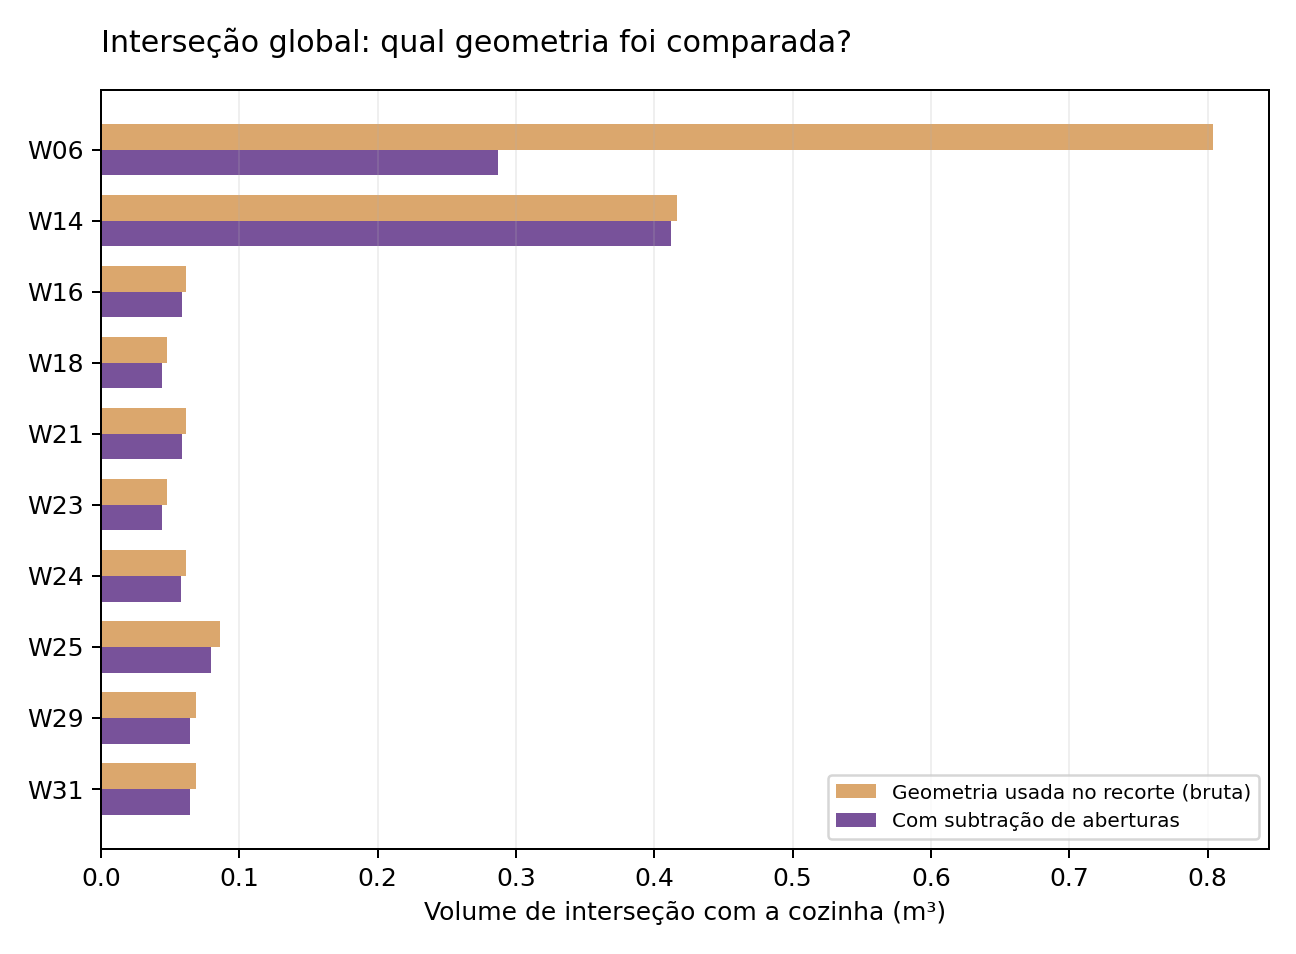

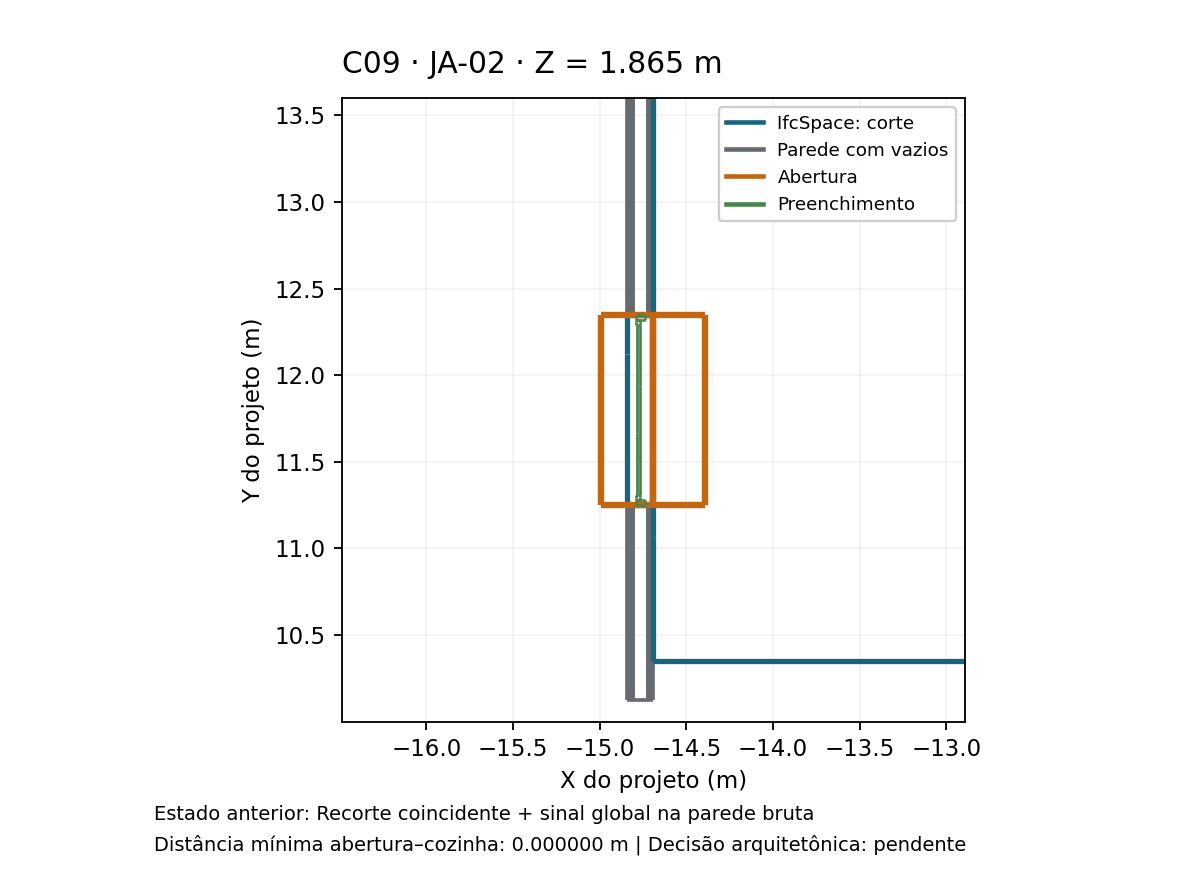

Galeria: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\bim-ontology-CIV2155\consultas\conferencia_ifc2sb_v01\saida_executada\Conferencia_Geometrica_Cozinha.html


In [5]:
from visualizar import draw
draw(saida)
from IPython.display import display,Image
display(Image(filename=str(saida/'figuras/Comparacao_Volumes_Paredes.png'),width=760))
display(Image(filename=str(saida/'figuras/C09.png'),width=760))
print('Galeria:',saida/'Conferencia_Geometrica_Cozinha.html')


## 6. Limites da interpretação e controle final

Distância zero, interseção volumétrica e coincidência entre superfícies respondem a perguntas diferentes. Subtrair a abertura torna esperado o volume local zero em muitos casos; isso não prova ausência de problema arquitetônico nem confirma o cômodo atendido.

A conferência é interna ao mesmo modelo e às mesmas bibliotecas. A leitura independente em planta/cortes e a escolha do predicado arquitetônico continuam pendentes. Nenhuma associação é promovida automaticamente a `bot:containsElement` ou `bot:adjacentElement` e o grafo anterior é preservado.

In [6]:
assert resultado['original_preservado'] and resultado['piloto_preservado'] and not resultado['erros']
assert len(resultado['casos'])==24 and len(resultado['paredes'])==34
assert controles['aprovados']==4
assert sha(ifc)==resultado['sha256_IFC'] and sha(piloto)==resultado['sha256_piloto']
print('24 casos e 34 paredes conferidos; quatro controles aprovados; entradas preservadas.')
print('Decisão arquitetônica: pendente em todos os casos.')


24 casos e 34 paredes conferidos; quatro controles aprovados; entradas preservadas.
Decisão arquitetônica: pendente em todos os casos.
